# ICT 4442 – ViT-B/16 for AI-Generated Face Detection

**Owner:** Anjney Jeswal  
**Registration number:** 230953236  
**Task:** Binary classification of real and AI-generated face images using an ImageNet-pretrained Vision Transformer (ViT-B/16).

## Before running
1. In Kaggle, create a new Notebook and attach the **140k Real and Fake Faces** dataset (`xhlulu`).
2. Set the Notebook accelerator to **GPU** (recommended: T4 or better).
3. Enable Internet in Notebook settings if the pretrained torchvision weights are not already cached, so ImageNet weights can be downloaded.
4. Run the cells from top to bottom.

The notebook first runs a **balanced subset experiment** with up to 5,000 images per class in each split, matching the preliminary execution plan in the interim report. For a full-data experiment, set `LIMIT_PER_CLASS = None` in the configuration cell and rerun from the data-loading cell onward. Clearly label subset and full-data results separately in the report.

**Integrity note:** The notebook does not contain fabricated results. Metrics and plots are created only after the model is actually trained and evaluated.

## 1. Imports and reproducibility

In [1]:
import os
import json
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: GPU not detected. ViT-B/16 training on CPU may be very slow. Enable a GPU accelerator in Kaggle.")

PyTorch: 2.11.0+cu128
Device: cuda


## 2. Experiment configuration

In [2]:
# Kaggle's expected folder from the interim report.
# The notebook also searches common nested train/valid(or val)/test folder layouts.
DATA_ROOT = Path("/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake")

OUTPUT_DIR = Path("/kaggle/working/vit_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
LIMIT_PER_CLASS = 5000   # Set to None for all available images in each class and split.
MAX_EPOCHS = 12          # 2 frozen-head warm-up epochs + up to 10 fine-tuning epochs.
WARMUP_EPOCHS = 2
HEAD_LR = 1e-3
FINETUNE_LR = 2e-5
WEIGHT_DECAY = 0.01
EARLY_STOPPING_PATIENCE = 3
THRESHOLD = 0.5

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

CONFIG = {
    "model": "torchvision ViT-B/16",
    "pretrained_weights": "ImageNet ViT_B_16_Weights.IMAGENET1K_V1",
    "input_size": IMAGE_SIZE,
    "patch_size": 16,
    "num_patches": 196,
    "embedding_dim": 768,
    "transformer_blocks": 12,
    "attention_heads": 12,
    "mlp_dimension": 3072,
    "head_warmup_epochs": WARMUP_EPOCHS,
    "head_learning_rate": HEAD_LR,
    "fine_tuning_learning_rate": FINETUNE_LR,
    "fine_tuned_encoder_blocks": 2,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "decision_threshold": THRESHOLD,
    "seed": SEED,
    "limit_per_class_per_split": LIMIT_PER_CLASS,
    "positive_class": "fake",
    "label_mapping": {"real": 0, "fake": 1}
}
print(json.dumps(CONFIG, indent=2))

{
  "model": "torchvision ViT-B/16",
  "pretrained_weights": "ImageNet ViT_B_16_Weights.IMAGENET1K_V1",
  "input_size": 224,
  "patch_size": 16,
  "num_patches": 196,
  "embedding_dim": 768,
  "transformer_blocks": 12,
  "attention_heads": 12,
  "mlp_dimension": 3072,
  "head_warmup_epochs": 2,
  "head_learning_rate": 0.001,
  "fine_tuning_learning_rate": 2e-05,
  "fine_tuned_encoder_blocks": 2,
  "weight_decay": 0.01,
  "batch_size": 32,
  "max_epochs": 12,
  "early_stopping_patience": 3,
  "decision_threshold": 0.5,
  "seed": 42,
  "limit_per_class_per_split": 5000,
  "positive_class": "fake",
  "label_mapping": {
    "real": 0,
    "fake": 1
  }
}


## 3. Locate and validate the dataset

In [3]:
def has_expected_split_layout(path: Path) -> bool:
    if not path.is_dir():
        return False
    names = {p.name.lower(): p for p in path.iterdir() if p.is_dir()}
    train_ok = "train" in names
    valid_ok = "valid" in names or "val" in names or "validation" in names
    test_ok = "test" in names
    return train_ok and valid_ok and test_ok


def find_dataset_root(preferred: Path) -> Path:
    if has_expected_split_layout(preferred):
        return preferred

    # Search attached Kaggle datasets and common nested directories.
    search_roots = [Path("/kaggle/input")]
    if preferred.exists():
        search_roots.insert(0, preferred)

    candidates = []
    for base in search_roots:
        if not base.exists():
            continue
        if has_expected_split_layout(base):
            candidates.append(base)
        for p in base.rglob("*"):
            if p.is_dir() and p.name.lower() in {"real-vs-fake", "real_vs_fake", "real-and-fake-faces"}:
                if has_expected_split_layout(p):
                    candidates.append(p)
        # Also inspect a bounded set of likely roots without assuming a fixed nesting name.
        for p in base.glob("*/*/*"):
            if p.is_dir() and has_expected_split_layout(p):
                candidates.append(p)

    unique = list(dict.fromkeys(candidates))
    if unique:
        return unique[0]
    raise FileNotFoundError(
        "Could not find train, valid/val/validation, and test folders. "
        "Check that the Kaggle dataset is attached and update DATA_ROOT to the folder containing those splits."
    )


def normalise_split_names(root: Path):
    dirs = {p.name.lower(): p for p in root.iterdir() if p.is_dir()}
    train_dir = dirs.get("train")
    valid_dir = dirs.get("valid") or dirs.get("val") or dirs.get("validation")
    test_dir = dirs.get("test")
    return train_dir, valid_dir, test_dir

DATA_ROOT = find_dataset_root(DATA_ROOT)
TRAIN_DIR, VALID_DIR, TEST_DIR = normalise_split_names(DATA_ROOT)
print("Dataset root:", DATA_ROOT)
print("Train:", TRAIN_DIR)
print("Validation:", VALID_DIR)
print("Test:", TEST_DIR)

for split_name, split_dir in [("train", TRAIN_DIR), ("validation", VALID_DIR), ("test", TEST_DIR)]:
    subdirs = sorted([p.name for p in split_dir.iterdir() if p.is_dir()])
    print(f"{split_name} class folders:", subdirs)
    if len(subdirs) < 2:
        raise ValueError(f"Expected at least two class folders in {split_dir}. Found: {subdirs}")

Dataset root: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
Train: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train
Validation: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/valid
Test: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test
train class folders: ['fake', 'real']
validation class folders: ['fake', 'real']
test class folders: ['fake', 'real']


## 4. Preprocessing and data loaders

In [4]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.10, scale=(0.02, 0.08), ratio=(0.3, 3.3), value="random")
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class RealFakeImageFolder(datasets.ImageFolder):
    """ImageFolder wrapper with the project's canonical labels: real=0, fake=1."""
    def __init__(self, root, transform=None):
        super().__init__(root=str(root), transform=transform)
        lower_to_original = {name.lower(): idx for name, idx in self.class_to_idx.items()}
        real_matches = [idx for name, idx in lower_to_original.items() if "real" in name]
        fake_matches = [idx for name, idx in lower_to_original.items() if "fake" in name]
        if not real_matches or not fake_matches:
            raise ValueError(
                f"Could not identify real/fake folders in {root}. Found classes: {self.classes}. "
                "Expected folder names containing 'real' and 'fake'."
            )
        self.real_original_idx = real_matches[0]
        self.fake_original_idx = fake_matches[0]

    def __getitem__(self, index):
        image, original_target = super().__getitem__(index)
        canonical_target = 1 if original_target == self.fake_original_idx else 0
        return image, canonical_target


def balanced_indices(imagefolder_dataset, limit_per_class=None):
    if limit_per_class is None:
        return list(range(len(imagefolder_dataset)))
    real_indices, fake_indices = [], []
    for i, (_, original_label) in enumerate(imagefolder_dataset.samples):
        if original_label == imagefolder_dataset.real_original_idx:
            real_indices.append(i)
        elif original_label == imagefolder_dataset.fake_original_idx:
            fake_indices.append(i)
    random.Random(SEED).shuffle(real_indices)
    random.Random(SEED + 1).shuffle(fake_indices)
    return real_indices[:limit_per_class] + fake_indices[:limit_per_class]

train_base = RealFakeImageFolder(TRAIN_DIR, transform=train_transform)
valid_base = RealFakeImageFolder(VALID_DIR, transform=eval_transform)
test_base = RealFakeImageFolder(TEST_DIR, transform=eval_transform)

train_indices = balanced_indices(train_base, LIMIT_PER_CLASS)
valid_indices = balanced_indices(valid_base, LIMIT_PER_CLASS)
test_indices = balanced_indices(test_base, LIMIT_PER_CLASS)

train_ds = Subset(train_base, train_indices)
valid_ds = Subset(valid_base, valid_indices)
test_ds = Subset(test_base, test_indices)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": (DEVICE.type == "cuda"),
    "persistent_workers": (NUM_WORKERS > 0)
}
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
valid_loader = DataLoader(valid_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

split_counts = {
    "train": {"total": len(train_ds), "real": sum(train_base.samples[i][1] == train_base.real_original_idx for i in train_indices), "fake": sum(train_base.samples[i][1] == train_base.fake_original_idx for i in train_indices)},
    "validation": {"total": len(valid_ds), "real": sum(valid_base.samples[i][1] == valid_base.real_original_idx for i in valid_indices), "fake": sum(valid_base.samples[i][1] == valid_base.fake_original_idx for i in valid_indices)},
    "test": {"total": len(test_ds), "real": sum(test_base.samples[i][1] == test_base.real_original_idx for i in test_indices), "fake": sum(test_base.samples[i][1] == test_base.fake_original_idx for i in test_indices)}
}
print(json.dumps(split_counts, indent=2))
if any(v["real"] == 0 or v["fake"] == 0 for v in split_counts.values()):
    raise ValueError("A split is missing real or fake images. Check the folder layout and class names.")

{
  "train": {
    "total": 10000,
    "real": 5000,
    "fake": 5000
  },
  "validation": {
    "total": 10000,
    "real": 5000,
    "fake": 5000
  },
  "test": {
    "total": 10000,
    "real": 5000,
    "fake": 5000
  }
}


## 5. Build the pretrained ViT-B/16 model

In [5]:
# Download ImageNet-pretrained ViT-B/16 weights if they are not already cached.
weights = ViT_B_16_Weights.IMAGENET1K_V1
model = vit_b_16(weights=weights)

# Replace the original 1000-class head with a single binary logit.
model.heads.head = nn.Linear(model.heads.head.in_features, 1)

# Freeze the pretrained model for the head warm-up stage.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.heads.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY
)

print(model.__class__.__name__)
print("Encoder blocks:", len(model.encoder.layers))
print("Trainable parameters during warm-up:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 208MB/s]


VisionTransformer
Encoder blocks: 12
Trainable parameters during warm-up: 769


## 6. Training and validation functions

In [6]:
def run_train_epoch(model, loader, optimizer, criterion):
    model.train()
    # Keep frozen encoder layers in eval mode; the trainable head remains in train mode.
    if WARMUP_ACTIVE:
        model.encoder.eval()
        model.heads.train()
    else:
        model.encoder.eval()
        for layer in model.encoder.layers[-2:]:
            layer.train()
        model.heads.train()

    total_loss = 0.0
    all_labels, all_probs = [], []
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.float().view(-1, 1).to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        probs = torch.sigmoid(logits.detach()).view(-1).cpu().numpy()
        all_probs.extend(probs.tolist())
        all_labels.extend(labels.view(-1).detach().cpu().numpy().astype(int).tolist())

    predictions = (np.array(all_probs) >= THRESHOLD).astype(int)
    return total_loss / len(loader.dataset), f1_score(all_labels, predictions, zero_division=0)


@torch.no_grad()
def evaluate_loader(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    all_labels, all_probs = [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels_device = labels.float().view(-1, 1).to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            if criterion is not None:
                loss = criterion(logits, labels_device)
                total_loss += loss.item() * images.size(0)
        all_probs.extend(torch.sigmoid(logits).view(-1).cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().astype(int).tolist())
    probs = np.asarray(all_probs)
    labels = np.asarray(all_labels)
    preds = (probs >= THRESHOLD).astype(int)
    loss_value = total_loss / len(loader.dataset) if criterion is not None else None
    return {
        "loss": loss_value,
        "labels": labels,
        "probabilities": probs,
        "predictions": preds,
        "f1": f1_score(labels, preds, zero_division=0)
    }

history = {"epoch": [], "phase": [], "train_loss": [], "train_f1": [], "val_loss": [], "val_f1": []}
BEST_VAL_F1 = -1.0
BEST_EPOCH = None
BEST_CHECKPOINT = OUTPUT_DIR / "best_vit.pt"
WARMUP_ACTIVE = True


def save_best_checkpoint(epoch, val_f1):
    torch.save({
        "epoch": epoch,
        "val_f1": float(val_f1),
        "model_state_dict": model.state_dict(),
        "config": CONFIG
    }, BEST_CHECKPOINT)


def train_one_epoch(epoch, phase):
    train_loss, train_f1 = run_train_epoch(model, train_loader, optimizer, criterion)
    val = evaluate_loader(model, valid_loader, criterion)
    history["epoch"].append(epoch)
    history["phase"].append(phase)
    history["train_loss"].append(float(train_loss))
    history["train_f1"].append(float(train_f1))
    history["val_loss"].append(float(val["loss"]))
    history["val_f1"].append(float(val["f1"]))
    print(f"Epoch {epoch:02d} | {phase:10s} | train loss {train_loss:.4f} | val loss {val['loss']:.4f} | val F1(fake) {val['f1']:.4f}")
    return val["f1"]


## 7. Train: 2-epoch head warm-up, then fine-tune final 2 encoder blocks

In [7]:
start_time = time.time()

# Stage 1: warm up the binary classification head while encoder weights are frozen.
WARMUP_ACTIVE = True
for epoch in range(1, WARMUP_EPOCHS + 1):
    val_f1 = train_one_epoch(epoch, "head_warmup")
    if val_f1 > BEST_VAL_F1:
        BEST_VAL_F1 = val_f1
        BEST_EPOCH = epoch
        save_best_checkpoint(epoch, val_f1)

# Stage 2: unfreeze only the last two Transformer encoder blocks and the binary head.
WARMUP_ACTIVE = False
for parameter in model.parameters():
    parameter.requires_grad = False
for layer in model.encoder.layers[-2:]:
    for parameter in layer.parameters():
        parameter.requires_grad = True
for parameter in model.heads.parameters():
    parameter.requires_grad = True

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=FINETUNE_LR,
    weight_decay=WEIGHT_DECAY
)

stale_epochs = 0
for epoch in range(WARMUP_EPOCHS + 1, MAX_EPOCHS + 1):
    val_f1 = train_one_epoch(epoch, "fine_tuning")
    if val_f1 > BEST_VAL_F1:
        BEST_VAL_F1 = val_f1
        BEST_EPOCH = epoch
        stale_epochs = 0
        save_best_checkpoint(epoch, val_f1)
    else:
        stale_epochs += 1
    if stale_epochs >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping: validation F1 did not improve for {EARLY_STOPPING_PATIENCE} consecutive fine-tuning epochs.")
        break

elapsed_minutes = (time.time() - start_time) / 60
print(f"Training finished in {elapsed_minutes:.1f} minutes")
print("Best epoch:", BEST_EPOCH, "Best validation F1:", round(BEST_VAL_F1, 4))
if not BEST_CHECKPOINT.exists():
    raise RuntimeError("No checkpoint was saved. Check the training output for errors.")

/tmp/ipykernel_23/4248539038.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/4248539038.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 01 | head_warmup | train loss 0.5274 | val loss 0.5093 | val F1(fake) 0.7027


/tmp/ipykernel_23/4248539038.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/4248539038.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 02 | head_warmup | train loss 0.4248 | val loss 0.4438 | val F1(fake) 0.7872


/tmp/ipykernel_23/4248539038.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/4248539038.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 03 | fine_tuning | train loss 0.3188 | val loss 0.3123 | val F1(fake) 0.8601


... (14 outputs left out)

/tmp/ipykernel_23/4248539038.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/4248539038.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 11 | fine_tuning | train loss 0.0422 | val loss 0.2516 | val F1(fake) 0.9156


/tmp/ipykernel_23/4248539038.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/4248539038.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 12 | fine_tuning | train loss 0.0450 | val loss 0.2497 | val F1(fake) 0.9135
Early stopping: validation F1 did not improve for 3 consecutive fine-tuning epochs.
Training finished in 32.0 minutes
Best epoch: 9 Best validation F1: 0.9327


## 8. Save training history and configuration

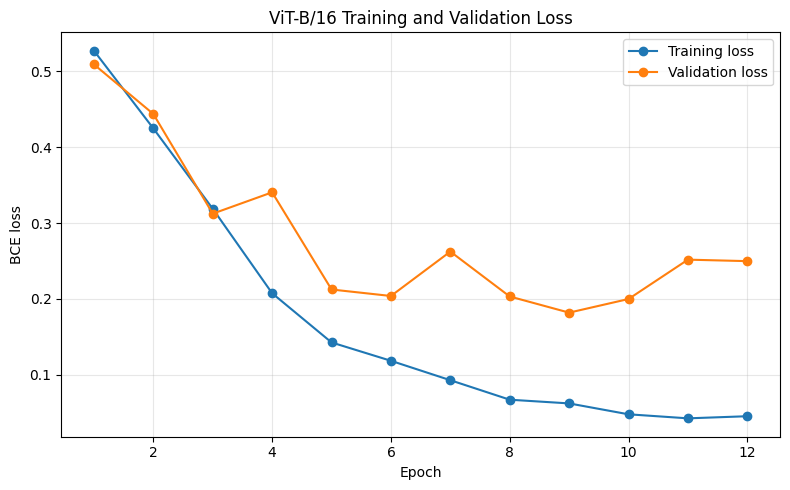

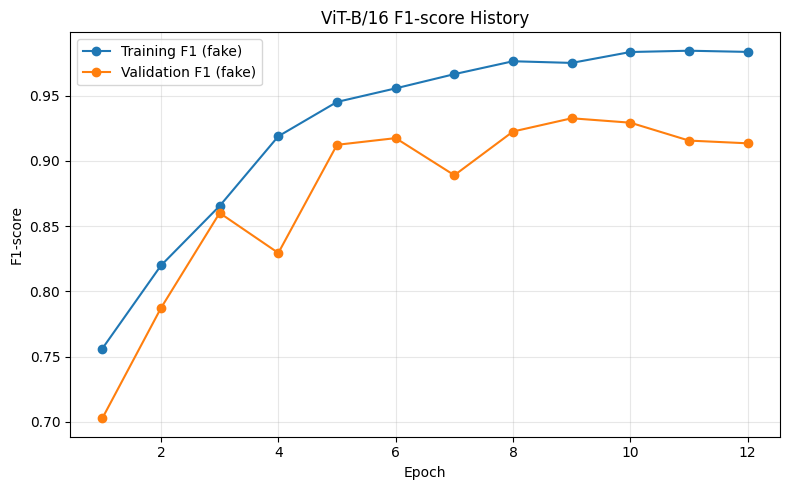

Saved training history and config to: /kaggle/working/vit_outputs


In [8]:
history_df = pd.DataFrame(history)
history_csv = OUTPUT_DIR / "training_history.csv"
history_df.to_csv(history_csv, index=False)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("ViT-B/16 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curve.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_f1"], marker="o", label="Training F1 (fake)")
plt.plot(history_df["epoch"], history_df["val_f1"], marker="o", label="Validation F1 (fake)")
plt.xlabel("Epoch")
plt.ylabel("F1-score")
plt.title("ViT-B/16 F1-score History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "f1_curve.png", dpi=200)
plt.show()

CONFIG["dataset_root"] = str(DATA_ROOT)
CONFIG["split_counts"] = split_counts
CONFIG["best_epoch"] = int(BEST_EPOCH)
CONFIG["best_validation_f1"] = float(BEST_VAL_F1)
CONFIG["training_minutes"] = float(elapsed_minutes)
CONFIG["run_type"] = "balanced_subset" if LIMIT_PER_CLASS is not None else "full_dataset"
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print("Saved training history and config to:", OUTPUT_DIR)

In [9]:
from pathlib import Path

output_dir = Path("/kaggle/working/vit_outputs")

print("Output directory exists:", output_dir.exists())

if output_dir.exists():
    print("\nFiles currently saved:")
    for file in sorted(output_dir.iterdir()):
        print(file.name, "-", round(file.stat().st_size / (1024**2), 2), "MB")

    checkpoint = output_dir / "best_vit.pt"
    print("\nBEST CHECKPOINT EXISTS:", checkpoint.exists())
else:
    print("No saved output directory found.")

Output directory exists: True

Files currently saved:
best_vit.pt - 327.36 MB
config.json - 0.0 MB
f1_curve.png - 0.09 MB
training_curve.png - 0.09 MB
training_history.csv - 0.0 MB

BEST CHECKPOINT EXISTS: True


## 9. Evaluate the best checkpoint once on the held-out test split

In [10]:
checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_result = evaluate_loader(model, test_loader, criterion=None)
y_true = test_result["labels"]       # canonical labels: real=0, fake=1
y_prob = test_result["probabilities"]
y_pred = test_result["predictions"]

metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_fake": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
    "recall_fake": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
    "f1_fake": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) == 2 else None,
    "decision_threshold": THRESHOLD,
    "best_checkpoint_epoch": int(checkpoint["epoch"]),
    "best_validation_f1": float(checkpoint["val_f1"]),
    "test_examples": int(len(y_true)),
    "test_real_examples": int((y_true == 0).sum()),
    "test_fake_examples": int((y_true == 1).sum()),
    "run_type": CONFIG["run_type"],
    "seed": SEED
}

print("TEST METRICS")
print(json.dumps(metrics, indent=2))
print("\nClassification report (fake is the positive class):")
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=["real", "fake"], zero_division=0))

with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Preserve the exact paths corresponding to the subset used in the test loader.
test_paths = [test_base.samples[i][0] for i in test_indices]
prediction_df = pd.DataFrame({
    "image_path": test_paths,
    "true_label": np.where(y_true == 1, "fake", "real"),
    "predicted_label": np.where(y_pred == 1, "fake", "real"),
    "fake_probability": y_prob,
    "correct": (y_true == y_pred)
})
prediction_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Saved test metrics and predictions.")

/tmp/ipykernel_23/4248539038.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


TEST METRICS
{
  "accuracy": 0.9349,
  "precision_fake": 0.9281354597361685,
  "recall_fake": 0.9428,
  "f1_fake": 0.9354102589542613,
  "roc_auc": 0.98361216,
  "decision_threshold": 0.5,
  "best_checkpoint_epoch": 9,
  "best_validation_f1": 0.9327229299363057,
  "test_examples": 10000,
  "test_real_examples": 5000,
  "test_fake_examples": 5000,
  "run_type": "balanced_subset",
  "seed": 42
}

Classification report (fake is the positive class):
              precision    recall  f1-score   support

        real       0.94      0.93      0.93      5000
        fake       0.93      0.94      0.94      5000

    accuracy                           0.93     10000
   macro avg       0.94      0.93      0.93     10000
weighted avg       0.94      0.93      0.93     10000

Saved test metrics and predictions.


## 10. Confusion matrix and ROC curve

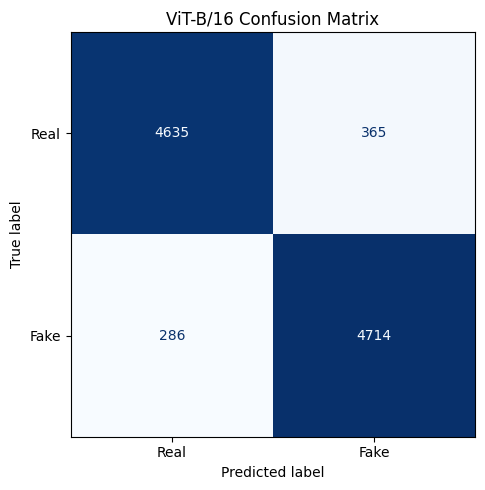

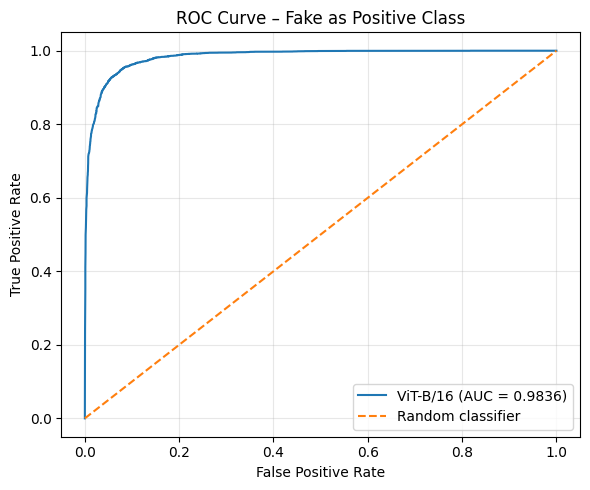

In [11]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Real", "Fake"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("ViT-B/16 Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

if len(np.unique(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=1)
    auc_value = roc_auc_score(y_true, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"ViT-B/16 (AUC = {auc_value:.4f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve – Fake as Positive Class")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=200)
    plt.show()
else:
    print("ROC curve skipped because the test set contains only one class.")

## 11. Inspect false positives and false negatives

In [12]:
false_positives = prediction_df[(prediction_df.true_label == "real") & (prediction_df.predicted_label == "fake")].sort_values("fake_probability", ascending=False)
false_negatives = prediction_df[(prediction_df.true_label == "fake") & (prediction_df.predicted_label == "real")].sort_values("fake_probability", ascending=True)

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
print("\nTop false positives:")
display(false_positives.head(10))
print("\nTop false negatives:")
display(false_negatives.head(10))

# Save a compact list for manual inspection in the report.
error_rows = pd.concat([
    false_positives.head(10).assign(error_type="false_positive"),
    false_negatives.head(10).assign(error_type="false_negative")
], ignore_index=True)
error_rows.to_csv(OUTPUT_DIR / "misclassified_examples.csv", index=False)
print("Saved misclassified_examples.csv. Inspect the image paths before writing causal explanations.")

False positives: 365
False negatives: 286

Top false positives:


,image_path,true_label,predicted_label,fake_probability,correct
2377,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,1.000000,False
3345,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,1.000000,False
3475,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.999512,False
1204,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.999512,False
333,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.999512,False
4554,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.998535,False
951,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.998535,False
4393,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.997559,False
2537,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.997070,False
4636,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,real,fake,0.997070,False



Top false negatives:


,image_path,true_label,predicted_label,fake_probability,correct
6820,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.000038,False
8259,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.000730,False
8025,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.000974,False
6944,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.001260,False
7685,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.001875,False
8757,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.001987,False
5053,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.002541,False
9276,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.002958,False
8555,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.003040,False
5580,/kaggle/input/datasets/xhlulu/140k-real-and-fa...,fake,real,0.003147,False


Saved misclassified_examples.csv. Inspect the image paths before writing causal explanations.


## 12. Optional attention-rollout visualisation

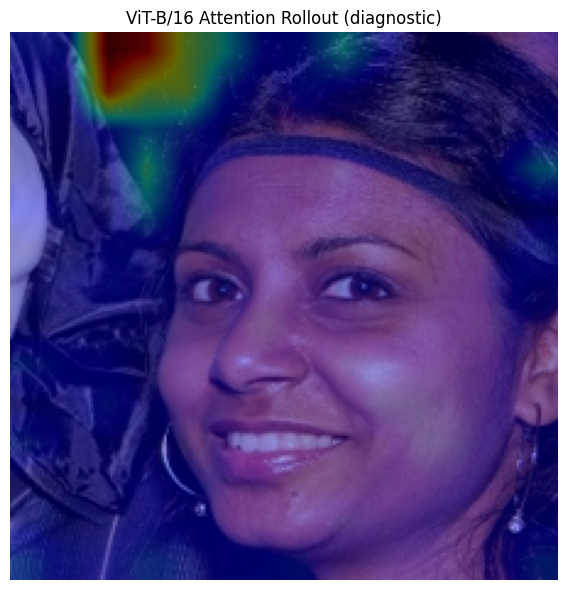

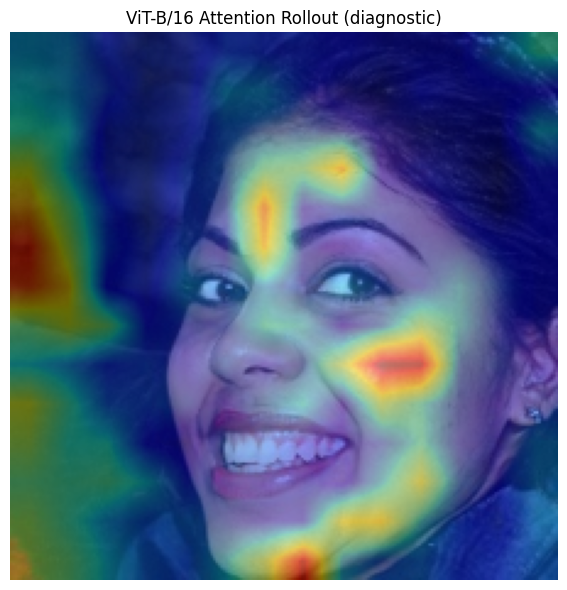

In [13]:
# Attention rollout is a diagnostic view, not a causal explanation of model reasoning.
# This cell attempts to capture the attention matrices in torchvision's MultiheadAttention blocks.
# If the installed torchvision version does not expose them in the expected way, the rest of the experiment remains valid.

attention_dir = OUTPUT_DIR / "attention_rollout"
attention_dir.mkdir(exist_ok=True)


def save_attention_rollout(image_path, output_path):
    from types import MethodType

    pil_image = Image.open(image_path).convert("RGB")
    tensor = eval_transform(pil_image).unsqueeze(0).to(DEVICE)
    saved_original_forwards = []
    captured = []

    try:
        for block in model.encoder.layers:
            mha = block.self_attention
            original_forward = mha.forward
            saved_original_forwards.append((mha, original_forward))

            def wrapped_forward(this, *args, __orig=original_forward, **kwargs):
                kwargs["need_weights"] = True
                kwargs["average_attn_weights"] = True
                out, weights = __orig(*args, **kwargs)
                if weights is not None:
                    captured.append(weights.detach().float().cpu())
                return out, weights

            mha.forward = MethodType(wrapped_forward, mha)

        with torch.no_grad():
            _ = model(tensor)

    finally:
        for mha, original_forward in saved_original_forwards:
            mha.forward = original_forward

    if not captured:
        raise RuntimeError("No attention weights were captured by this torchvision build.")

    # Average heads are returned by MultiheadAttention. Roll attention through layers.
    joint = torch.eye(captured[0].shape[-1])
    for attn in captured:
        a = attn[0]
        a = a + torch.eye(a.shape[-1])
        a = a / a.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        joint = a @ joint

    cls_to_patches = joint[0, 1:]
    side = int(np.sqrt(cls_to_patches.numel()))
    if side * side != cls_to_patches.numel():
        raise RuntimeError("Unexpected number of image patch tokens in attention output.")
    heat = cls_to_patches.reshape(1, 1, side, side)
    heat = torch.nn.functional.interpolate(heat, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0].numpy()
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)

    original = pil_image.resize((IMAGE_SIZE, IMAGE_SIZE))
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(original)
    ax.imshow(heat, cmap="jet", alpha=0.40)
    ax.axis("off")
    ax.set_title("ViT-B/16 Attention Rollout (diagnostic)")
    plt.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Use up to two correctly/incorrectly classified samples when available.
sample_paths = []
if len(false_positives):
    sample_paths.append(false_positives.iloc[0]["image_path"])
if len(false_negatives):
    sample_paths.append(false_negatives.iloc[0]["image_path"])
if not sample_paths and len(prediction_df):
    sample_paths.append(prediction_df.iloc[0]["image_path"])

for idx, path in enumerate(sample_paths[:2], start=1):
    try:
        save_attention_rollout(path, attention_dir / f"attention_rollout_{idx}.png")
    except Exception as exc:
        print("Attention rollout could not be generated:", repr(exc))
        print("This optional diagnostic can be omitted; the main evaluation outputs are unaffected.")

## 13. Final output audit

In [14]:
# Update the saved config with final test information.
CONFIG["test_metrics"] = metrics
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

expected_files = [
    "best_vit.pt",
    "config.json",
    "test_metrics.json",
    "test_predictions.csv",
    "confusion_matrix.png",
    "roc_curve.png",
    "training_curve.png",
    "training_history.csv",
    "misclassified_examples.csv"
]
print("Output directory:", OUTPUT_DIR)
for filename in expected_files:
    p = OUTPUT_DIR / filename
    print(f"{'OK' if p.exists() else 'MISSING'}  {filename}")

print("\nAttention rollout files:")
for p in sorted(attention_dir.glob("*.png")):
    print("OK ", p.name)

# Zip the evidence folder so it can be downloaded from the Kaggle Output panel.
archive_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("\nEvidence archive:", archive_path)
print("Download vit_outputs.zip from the Kaggle Notebook Output panel after the run finishes.")

Output directory: /kaggle/working/vit_outputs
OK  best_vit.pt
OK  config.json
OK  test_metrics.json
OK  test_predictions.csv
OK  confusion_matrix.png
OK  roc_curve.png
OK  training_curve.png
OK  training_history.csv
OK  misclassified_examples.csv

Attention rollout files:
OK  attention_rollout_1.png
OK  attention_rollout_2.png

Evidence archive: /kaggle/working/vit_outputs.zip
Download vit_outputs.zip from the Kaggle Notebook Output panel after the run finishes.


In [15]:
import os
from pathlib import Path

work = Path("/kaggle/working")

print("Files in working directory:")
for item in work.iterdir():
    print(item.name, round(item.stat().st_size / (1024**2), 2), "MB")

zip_file = work / "vit_outputs.zip"
print("\nZIP exists:", zip_file.exists())

if zip_file.exists():
    print("ZIP size:", round(zip_file.stat().st_size / (1024**2), 2), "MB")

Files in working directory:
__notebook__.ipynb 1.12 MB
vit_outputs.zip 305.19 MB
vit_outputs 0.0 MB

ZIP exists: True
ZIP size: 305.19 MB
